In [1]:
#importing necessary packages
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
#reading the provided .csv dataset
data=pd.read_csv("/content/diabetes.csv")

In [3]:
data.shape

(768, 9)

In [4]:
data.columns.tolist()
data.dtypes

,0
Pregnancies,int64
Glucose,int64
BloodPressure,int64
SkinThickness,int64
Insulin,int64
BMI,float64
DiabetesPedigreeFunction,float64
Age,int64
Outcome,int64


In [5]:
data.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [6]:
data.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


In [7]:
cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

In [8]:
data[cols] = data[cols].replace(0, np.nan)
data [cols] = data[cols].fillna(data[cols].mean())
(data[cols] == 0).sum()

,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0


In [9]:
data.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72.0,35.00000,155.548223,33.6,0.627,50,1
1,1,85.0,66.0,29.00000,155.548223,26.6,0.351,31,0
2,8,183.0,64.0,29.15342,155.548223,23.3,0.672,32,1
3,1,89.0,66.0,23.00000,94.000000,28.1,0.167,21,0
4,0,137.0,40.0,35.00000,168.000000,43.1,2.288,33,1


In [10]:
data['Outcome'].value_counts()

,count
Outcome,
0,500
1,268


In [11]:
data.select_dtypes(include='object').columns.tolist()

[]

In [12]:
#dividing the data into dependent and independent columns
x=data.drop(['Outcome'], axis=1) #input - features
y=data['Outcome'] #output - target variable

In [13]:
#splitting the data into - training and testing
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.25)
#25% of the data will be used for testing and rest 80% will be used for training purposes.

In [14]:
from sklearn.linear_model import LogisticRegression
#Logistic Regression algorithm is selected because the problem is a binary classification.

from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

In [15]:
model = LogisticRegression()

In [16]:
model.fit(x_train, y_train)
#training of the ML model on top of 80% of the data and by using Logistic Regression algo takes place

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression()

In [17]:
prediction = model.predict(x_test)

In [18]:
#checking the accuracy of the model
from sklearn.metrics import accuracy_score

In [19]:
y_train_pred = model.predict(x_train)
train_accuracy = accuracy_score(y_train, y_train_pred)
print("Training accuracy:", train_accuracy)

Training accuracy: 0.7760416666666666


In [20]:
prediction = model.predict(x_test)
test_accuracy = accuracy_score(y_test, prediction)
print("Test accuracy:", test_accuracy)

Test accuracy: 0.75


In [21]:
#Precision
precision = precision_score(y_test, prediction)
print("Precision:", round(precision, 4))

Precision: 0.7358


In [22]:
#Recall
recall = recall_score(y_test, prediction)
print("Recall:", round(recall, 4))

Recall: 0.5342


In [23]:
#F1-Score
f1 = f1_score(y_test, prediction)
print("F1-Score:", round(f1, 4))

F1-Score: 0.619


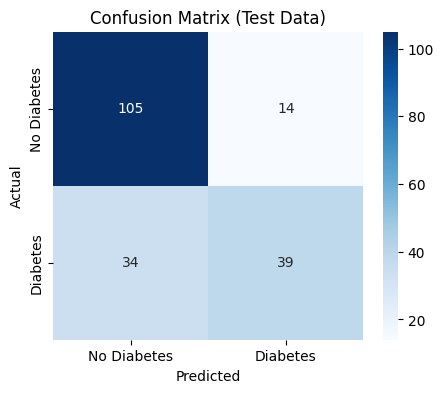

In [24]:
#Confusion Matrix
cm = confusion_matrix(y_test, prediction)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Diabetes', 'Diabetes'],
            yticklabels=['No Diabetes', 'Diabetes'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix (Test Data)')
plt.show()